## Debt Maturity, Term Premia, and Fiscal Inflation
Artur Doshchyn, Martin Ellison and Rigas Oikonomou (2026)


#### **Notation**

| Symbol | Definition |
|:--|:--|
| $C_t, N_t, P_t$ | Consumption, labor, and price level |
| $I_t, i_t$ | Gross short rate (level), short-rate deviation |
| $Q_t^L, q_t$ | Long-bond price (level), log-price deviation |
| $R_{t+1}^L, r_{t+1}^L$ | Gross long-bond return, log-return deviation |
| $y_t^L, tp_t$ | Long yield and term-premium deviations |
| $x_t, \pi_t$ | Output gap and inflation deviation |
| $d_t, D_t$ | Real-debt deviation and the lagged-debt state, $D_t=d_{t-1}$ |
| $\omega_t, \bar\omega, w_t$ | Long-debt share, its steady state, and its deviation |
| $\widetilde\omega, \delta, \xi$ | Risky-steady-state portfolio/return coefficients |
| $\alpha,\gamma,\eta,\mu$ | Arbitrageur share, risk aversion, habitat slope/intercept |
| $V_L$ | Conditional variance of the long-bond return |
| $z_t^m,z_t^f,z_t^x,z_t^p$ | Monetary, fiscal, demand, and cost-push shocks |

Theoretical expressions use mathematical symbols; code uses `w`, `D`, `Il`, `Ql`, and `Wl` for maturity-share deviation, lagged debt, and lagged policy rate, bond price, and maturity share. Distinguish $P_t$ (aggregate price level) from $D_t$ (lagged real-debt state). The household, Calvo, and mean–variance foundations below are illustrative rationalizations of the implemented linear model, not independently verified primitive-level equations from the paper.

#### **Model Structure**

$$
\underbrace{\text{Households and Calvo firms}}_{\text{New Keynesian block}}
+\underbrace{\text{Government debt and fiscal rule}}_{\text{Fiscal block}}
+\underbrace{\text{Arbitrageurs and habitat demand}}_{\text{Bond-market block}}
$$

$$
\omega_t\uparrow\;\Longrightarrow\; tp_t,\,q_t,\,r_t^B
\;\Longrightarrow\; x_t,\,\pi_t,\,d_t
$$

#### (1) **Household-가계의 효용극대화**

대표가계의 기본 효용을 다음과 같이 둬보자. (canonical NK benchmark).

$$
\max_{\{C_t,N_t,B_{t+1}\}}E_0\sum_{t=0}^{\infty}\beta^t
\left[\frac{C_t^{1-\varsigma}}{1-\varsigma}-\frac{N_t^{1+\varphi}}{1+\varphi}\right],\qquad
\beta\in(0,1).
$$

명목 예산제약과 Lagrangian:

$$
P_tC_t+\mathcal Q_t B_{t+1}\le W_tN_t+\mathcal X_t B_t+\Pi_t-T_t,
$$

$$
\mathcal L=E_0\sum_t\beta^t\left\{u(C_t,N_t)+\lambda_t\big[W_tN_t+\mathcal X_tB_t+\Pi_t-T_t-P_tC_t-\mathcal Q_tB_{t+1}\big]\right\}.
$$

소비와 노동의 FOC:

$$
C_t^{-\varsigma}=\lambda_tP_t,\qquad N_t^{\varphi}=\lambda_tW_t
\quad\Longrightarrow\quad \frac{W_t}{P_t}=N_t^{\varphi}C_t^{\varsigma}.
$$

무위험 1기간 채권 $\mathcal Q_t=I_t^{-1}$의 Euler equation:

$$
\lambda_t\mathcal Q_t=\beta E_t[\lambda_{t+1}],\qquad
1=\beta E_t\left[\frac{C_{t+1}^{-\varsigma}}{C_t^{-\varsigma}}
\frac{I_t}{\Pi_{t+1}}\right],\qquad \Pi_{t+1}=\frac{P_{t+1}}{P_t}.
$$

확실성 등가 또는 1차 근사에서:

$$
c_t=E_tc_{t+1}-\frac{1}{\varsigma}\left(i_t-E_t\pi_{t+1}-r_t^n\right).
$$

 `sigma`는 역탄력성 $\sigma\equiv1/\varsigma$에 해당하는 IS 계수를 의미한다.

#### **(2) Aggregate IS 장단기채 수익률의 소비 전달**

소비 전달은 단기 정책금리만이 아니라 "정부부채 포트폴리오의 실질수익률 $r_t^B$"가 "총수요"에 영향을 준다는 추가 모형가정을 사용한다.

$$
x_t=E_tx_{t+1}-\sigma\left(r_t^B-E_t\pi_{t+1}\right)+z_t^x
$$

선형화한 포트폴리오 수익률을 다음과 같이 정의해보자.

$$
r_t^B=(1-\widetilde\omega)i_t+
\widetilde\omega\big(\delta E_tq_{t+1}-q_t\big)+\xi w_t
$$

$$
\widetilde\omega\equiv\beta\bar R^L\bar\omega,\qquad
\xi\equiv\frac{\beta\bar R^L-1}{1-\bar\omega}.
$$

대입해보면,

$$
x_t=E_tx_{t+1}-\sigma\left[(1-\widetilde\omega)i_t
+\widetilde\omega\delta E_tq_{t+1}-\widetilde\omega q_t
+\xi w_t-E_t\pi_{t+1}\right]+z_t^x.
$$

이를 $A E_tX_{t+1}=BX_t$ 형태로 정리하면:

$$
E_tx_{t+1}-\sigma\widetilde\omega\delta E_tq_{t+1}
+\sigma E_t\pi_{t+1}=x_t-z_t^x
+\sigma(1-\widetilde\omega)i_t-\sigma\widetilde\omega q_t+\sigma\xi w_t
$$

** 이 식은 포트폴리오 수익률을 가계의 관련 실질금리로 연결하는 additional reduced-form transmission assumption이고, representative-agent Euler equation에서 기계적으로 도출되지 않았음

#### **(3) Firms- 독점적 경쟁과 Calvo 가격설정**

중간재 기업 $j\in[0,1]$, 최종재 CES aggregator:

$$
Y_t=\left(\int_0^1Y_t(j)^{\frac{\epsilon-1}{\epsilon}}dj\right)^{\frac{\epsilon}{\epsilon-1}},\qquad
Y_t(j)=\left(\frac{P_t(j)}{P_t}\right)^{-\epsilon}Y_t.
$$

생산기술과 실질한계비용:

$$
Y_t(j)=A_tN_t(j),\qquad MC_t=\frac{W_t}{P_tA_t}.
$$

각 분기 가격을 유지할 확률 $\vartheta$, 재설정할 확률 $1-\vartheta$. 재설정 가격 $P_t^*$의 목적함수는:

$$
\max_{P_t^*}E_t\sum_{h=0}^{\infty}(\beta\vartheta)^h
\Lambda_{t,t+h}\left[\frac{P_t^*}{P_{t+h}}-MC_{t+h}\right]
Y_{t+h}\left(\frac{P_t^*}{P_{t+h}}\right)^{-\epsilon}.
$$

가격지수 갱신식:

$$
P_t^{1-\epsilon}=\vartheta P_{t-1}^{1-\epsilon}
+(1-\vartheta)(P_t^*)^{1-\epsilon}.
$$

정상상태 주변 로그선형화 → 표준 NK Phillips curve:

$$
\pi_t=\beta E_t\pi_{t+1}+\lambda_{mc}\widehat{mc}_t+z_t^p,\quad
\lambda_{mc}=\frac{(1-\vartheta)(1-\beta\vartheta)}{\vartheta}
\ \text{(simple Calvo benchmark)}.
$$

$\widehat{mc}_t=\zeta x_t$를 가정하면 $\kappa=\lambda_{mc}\zeta$이고:

$$
\pi_t=\beta E_t\pi_{t+1}+\kappa x_t+z_t^p
$$

$$
\beta E_t\pi_{t+1}=\pi_t-\kappa x_t-z_t^p
$$

$\kappa=0.02$를 직접 calibration하며 $\vartheta,\epsilon,\zeta$를 별도로 추정하거나 계산 x

#### **(4) Government - 재정예산제약과 조세준칙**

명목 정부부채의 예산제약은 1) 신규 발행액, 2) 기존 부채 상환액, 3) 기초재정수지의 관계로 표현해보자.

$$
\text{Market value of newly issued liabilities}
=\text{Gross payoff on outstanding liabilities}-P_t S_t.
$$

실질 부채 $d_t$의 선형 재귀식:

$$
d_t=\left(\beta^{-1}-\tau\right)d_{t-1}
+\frac{\bar d}{\beta}\left(r_{t-1}^{B,\mathrm{real}}\right)+z_t^f,
$$

$$
r_{t-1}^{B,\mathrm{real}}=(1-\widetilde\omega)i_{t-1}
+\widetilde\omega(\delta q_t-q_{t-1})+\xi w_{t-1}-\pi_t.
$$

따라서:

$$
d_t=(\beta^{-1}-\tau)d_{t-1}+\frac{\bar d}{\beta}
\left[(1-\widetilde\omega)i_{t-1}
+\widetilde\omega(\delta q_t-q_{t-1})+\xi w_{t-1}-\pi_t\right]+z_t^f.
$$

$\tau$는 재정수지가 이전 부채에 반응하는 피드백 계수이다. 코드의 $\bar d=4$는 사용된 분기 GDP 정규화에 대응한다. 이 재귀식 자체는 기존 부채의 payoff와 과세 반응에 관한 특정 timing/normalization이 들어간 모델 식이므로, 일반적인 명목 예산제약으로부터 유일하게 결정되지는 않는다.

상태 정의 $D_t\equiv d_{t-1}$를 대입하면 코드의 상태방정식:

$$
E_tD_{t+1}=(\beta^{-1}-\tau)D_t+
\frac{\bar d}{\beta}\big[(1-\widetilde\omega)I_t^{lag}
+\widetilde\omega(\delta q_t-Q_t^{lag})+\xi W_t^{lag}-\pi_t\big]+z_t^f.
$$

#### **(5) Long bond - 장기채 가격·수익률·듀레이션**

장기채는 매 분기 쿠폰 $K$를 지급하고 남은 청구권이 $\rho_K$배로 감쇠하는 perpetuity로 표현함:

$$
Q_t^L=\frac{K+\rho_KQ_{t+1}^L}{R_{t+1}^L}
\quad\Longleftrightarrow\quad R_{t+1}^L=\frac{K+\rho_KQ_{t+1}^L}{Q_t^L}.
$$

정상상태에서 $\bar Q^L=1$로 정규화하면:

$$
\bar R^L=K+\rho_K,\qquad \delta\equiv\frac{\rho_K}{\bar R^L}\in(0,1).
$$

1차 로그선형화:

$$
\underbrace{r_{t+1}^L}_{\text{long return}}
=\underbrace{\delta q_{t+1}-q_t}_{\text{capital gain and purchase price}},
$$

$$
\underbrace{y_t^L}_{\text{long yield}}=-(1-\delta)q_t,\qquad
\underbrace{\mathcal D}_{\text{duration in years}}\approx\frac{1}{4(1-\delta)}.
$$

기대가설(EH) 장기수익률과 term premium의 정의:

$$
y_t^{EH}=(1-\delta)\sum_{h=0}^{\infty}\delta^h E_ti_{t+h},\qquad
tp_t=y_t^L-y_t^{EH}.
$$

여기서는 기대가설 수익률을 IRF 끝에서 역방향 재귀로 계산함:

$$
y_t^{EH}=(1-\delta)i_t+\delta y_{t+1}^{EH},\qquad y_H^{EH}=0.
$$


#### **(6) Arbitrageurs - 제한적 차익거래자의 위험보상**

차익거래자가 장기채 투자비중 $a_t$를 선택하고 평균-분산 목적을 갖는다고 가정함:

$$
\max_{a_t}\left\{a_t\big(E_tr_{t+1}^L-i_t\big)
-\frac{\gamma V_L}{2}a_t^2\right\},\qquad \gamma>0,
$$

$$
\frac{\partial}{\partial a_t}:\quad E_tr_{t+1}^L-i_t-\gamma V_La_t=0.
$$

따라서 최적 포지션:

$$
\boxed{a_t=\frac{E_tr_{t+1}^L-i_t}{\gamma V_L}},$$ 
$$
\underbrace{E_tr_{t+1}^L-i_t}_{\text{required excess return}}
=\underbrace{\gamma V_La_t}_{\text{risk compensation}}.
$$

로그가격을 이용하면 $E_tr_{t+1}^L-i_t=\delta E_tq_{t+1}-q_t-i_t$. 여기의 $V_L$은 $r^L$의 조건부 분산을 일정하게 근사한 값이다. 위험중립 비교실험 $\gamma=0$에서는 첫 번째 분수식을 사용하지 않고 $E_tr_{t+1}^L=i_t$라는 한계조건을 사용해야 한다. 

#### **(7) Preferred habitat- 채권수요와 시장청산**

장기채에 대한 preferred-habitat 투자자의 수요를 다음의 선형식으로 둠:

$$
h_t=\mu+\eta(y_t^L-i_t),\qquad \eta>0.
$$

포트폴리오 시장청산(총 장기채 공급 비중 $\omega_t$):

$$
\boxed{\omega_t=\alpha a_t+(1-\alpha)h_t}.
$$

차익거래 수요를 대입하면:

$$
\omega_t=\frac{\alpha}{\gamma V_L}
\big(E_tr_{t+1}^L-i_t\big)
+(1-\alpha)\big[\mu+\eta(y_t^L-i_t)\big].
$$

정상상태 초과수익률과 수익률 스프레드를 동일한 장기채 위험보상 $\overline{tp}$로 정규화한 경우:

$$
\bar\omega=\frac{\alpha}{\gamma V_L}\overline{tp}
+(1-\alpha)\left[\mu+\eta\overline{tp}\right].
$$

양변에 $\gamma V_L$을 곱하고 $\overline{tp}$를 모으면:

$$
\gamma V_L\left[\bar\omega-(1-\alpha)\mu\right]
=\left[\alpha+(1-\alpha)\eta\gamma V_L\right]\overline{tp},
$$

$$
\overline{tp}=\frac{\gamma V_L[\bar\omega-(1-\alpha)\mu]}
{\alpha+(1-\alpha)\eta\gamma V_L}.
$$

이것이 코드의 `tp` 식임. 위 정상상태 변환에는 장단기 스프레드와 예상 초과수익률의 동일시라는 정상상태 정규화가 필요함.

#### **Risky steady state / 정상상태 이자율과 가격계수**

가계의 정상상태 부채 포트폴리오 수익률 할인조건(코드의 정규화):

$$
1=\beta\bar I\big[(1-\bar\omega)+\bar\omega e^{\overline{tp}}\big],
$$

$$
\boxed{\bar I=\frac{1}{\beta(1-\bar\omega+\bar\omega e^{\overline{tp}})}},\qquad
\boxed{\bar R^L=\bar I e^{\overline{tp}}}.
$$

장기채 decay 및 포트폴리오 수익률의 선형화 계수:

$$
\delta=\frac{\rho_K}{\bar R^L},\qquad
\widetilde\omega=\beta\bar R^L\bar\omega,\qquad
\xi=\frac{\beta\bar R^L-1}{1-\bar\omega}.
$$

채권시장 선형화에 사용하는 편의계수:

$$
\boxed{\chi=\frac{\alpha}{\alpha+(1-\alpha)(1-\delta)\eta\gamma V_L}},
$$

$$
\boxed{\theta=1+\chi\left(\frac{1}{\alpha}-1\right)
\delta\eta\gamma V_L}.
$$

코드의 장기채 균형식은 다음과 같이 주어짐:

$$
\boxed{\chi\delta E_tq_{t+1}=q_t+\theta i_t+
\frac{\chi}{\alpha}\gamma V_Lw_t}.
$$

이는 위 수요체계와 장기채 가격식의 선형화에서 얻는 코드상의 *pricing restriction*임. 단, 원 논문의 수요가 수익률 $y_t^L-i_t$인지, 기대초과수익률인지, 그리고 수량변수의 단위가 무엇인지에 따라 전개계수가 달라짐. 따라서 $\chi,\theta$의 정확한 primitive-level 도출은 해당 시장청산 정규화를 추가로 특정해야 하며, 이 Notebook은 **구현된 최종 제한식**을 기준으로 함.

*This qualification is essential: the code's exact bond equation is treated as the calibrated equilibrium restriction, not claimed to follow uniquely from the illustrative household/arbitrageur primitives.*

#### **Monetary and fiscal rules / 정책 레짐**

통화정책 Taylor rule:

$$
\boxed{i_t=\phi_\pi\pi_t+\phi_xx_t+z_t^m}.
$$

재정정책은 실질 부채에 대한 반응계수 $\tau$로 표현됨:

$$
d_t=(\beta^{-1}-\tau)d_{t-1}+\text{valuation/return terms}+z_t^f.
$$

$$
\begin{array}{c|cc}
\text{Regime}&\phi_\pi&\tau\\\hline
\text{MD: monetary dominance}&1.5&0.0135\\
\text{FD: fiscal dominance}&0.8&0
\end{array}
$$

정책 레짐의 결정성과 물가경로는 Taylor coefficient 하나로 단정하지 않고 전체 $A,B$ 시스템의 generalized eigenvalues로 검증함. *Regime labels refer to the supplied calibration; determinacy is checked numerically.*

#### **Exogenous shocks / 외생 상태과정**

$$
z_{t+1}^j=\rho_j z_t^j+\varepsilon_{t+1}^j,
\qquad E[\varepsilon_t^j]=0,\qquad
\mathrm{Var}(\varepsilon_t^j)=\sigma_j^2,
$$

$$
j\in\{m,f,x,p,\omega\},\qquad
w_{t+1}=\rho_\omega w_t+\varepsilon_{t+1}^{\omega}.
$$

$$
\varepsilon_t\sim\mathcal N(0,\operatorname{diag}
(\sigma_m^2,\sigma_f^2,\sigma_x^2,\sigma_p^2,\sigma_\omega^2))
$$

독립 충격 가정은 코드의 $V_L$ 계산에서 공분산 교차항을 제거하는 조건임. *Shock innovations are treated as mutually orthogonal in the implemented variance mapping.*

### Collect equations / 전체 13식과 상태공간

$$
k_t=(z_t^m,z_t^f,z_t^x,z_t^p,w_t,D_t,I_t^{lag},Q_t^{lag},W_t^{lag})^\top,
$$

$$
u_t=(\pi_t,x_t,i_t,q_t)^\top,\qquad X_t=(k_t^\top,u_t^\top)^\top.
$$

첫 다섯 식: $E_tz_{t+1}^j=\rho_jz_t^j$. 그 다음 네 식은 부채와 세 개의 lag states:

$$
\begin{aligned}
E_tD_{t+1}&=(\beta^{-1}-\tau)D_t+\frac{\bar d}{\beta}
\big[(1-\widetilde\omega)I_t^{lag}+\widetilde\omega(\delta q_t-Q_t^{lag})
+\xi W_t^{lag}-\pi_t\big]+z_t^f,\\
E_tI_{t+1}^{lag}&=i_t,\\
E_tQ_{t+1}^{lag}&=q_t,\\
E_tW_{t+1}^{lag}&=w_t.
\end{aligned}
$$

마지막 네 식(NKPC, IS, Taylor, bond pricing):

$$
\begin{aligned}
\beta E_t\pi_{t+1}&=\pi_t-\kappa x_t-z_t^p,\\
E_tx_{t+1}-\sigma\widetilde\omega\delta E_tq_{t+1}+\sigma E_t\pi_{t+1}
&=x_t-z_t^x+\sigma(1-\widetilde\omega)i_t-\sigma\widetilde\omega q_t+\sigma\xi w_t,\\
0&=i_t-\phi_\pi\pi_t-\phi_xx_t-z_t^m,\\
\chi\delta E_tq_{t+1}&=q_t+\theta i_t+\frac{\chi}{\alpha}\gamma V_Lw_t.
\end{aligned}
$$

$$
\boxed{A E_tX_{t+1}=BX_t,\qquad A,B\in\mathbb R^{13\times13}.}
$$

이 13개 식은 아래 `solve_linear_model()`의 13행과 정확히 대응함. *These equations map one-for-one to the implemented matrix rows.*

#### **QZ + fixed point / 균형해 및 분산의 내생적 결정**

일반화 Schur decomposition:

$$
Q^*AZ=S,\qquad Q^*BZ=T,\qquad
\lambda_j=\frac{T_{jj}}{S_{jj}},\qquad |\lambda_j|<1\ \text{stable}.
$$

안정 부분공간을 $Z_s=\begin{bmatrix}Z_{11}\\Z_{21}\end{bmatrix}$로 분할하면:

$$
\boxed{u_t=Fk_t,\quad F=Z_{21}Z_{11}^{-1}},
$$

$$
\boxed{k_{t+1}=Gk_t,\quad
G=Z_{11}S_{11}^{-1}T_{11}Z_{11}^{-1}}.
$$

$$
\#\{|\lambda_j|<1\}=9=\dim(k_t),\qquad
\underbrace{A\begin{bmatrix}I\\F\end{bmatrix}G
-B\begin{bmatrix}I\\F\end{bmatrix}}_{\text{equilibrium residual}}=0.
$$

$\delta$와 $F$가 $V_L$에 의존하기 때문에 자기일관적 분산의 고정점이 필요함:

$$
r_{t+1}^L=\delta q_{t+1}-q_t,\qquad
q_t=F_qk_t,\qquad
k_{t+1}=Gk_t+B_\varepsilon\varepsilon_{t+1},
$$

$$
\operatorname{Var}_t(r_{t+1}^L)
=\delta^2\operatorname{Var}_t(q_{t+1})
=\delta^2\sum_{j\in\{m,f,x,p,\omega\}}
(F_{q,j}\sigma_j)^2.
$$

$$
\boxed{V_L=\mathcal T(V_L)=\delta(V_L)^2\sum_j
[F_{q,j}(V_L)\sigma_j]^2},
$$

$$
V_L^{(n+1)}=(1-\lambda)V_L^{(n)}+\lambda\mathcal T(V_L^{(n)}),
\qquad \lambda=0.5.
$$

*Risk-neutral solution: set $\gamma=0$ and solve the same linear system and fixed-point relation under that parameter restriction.*

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import ordqz
from IPython.display import display

# Publication-style figures: white canvas, boxed axes, discrete markers
plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9,
    'mathtext.fontset': 'dejavuserif',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': True, 'axes.spines.right': True,
    'axes.edgecolor': '#888888', 'axes.linewidth': 0.75,
    'axes.labelcolor': '#222222',
    'xtick.color': '#222222', 'ytick.color': '#222222',
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.size': 3, 'ytick.major.size': 3,
    'legend.frameon': True, 'legend.fancybox': False,
    'savefig.facecolor': 'white',
})
BLUE, RED = '#0000FF', '#FF0000'  # RGB(0,0,255), RGB(255,0,0)
NAVY, GRAY = BLUE, RED


## Calibration & State Variables

$$
k_t=(z_t^m,z_t^f,z_t^x,z_t^p,w_t,D_t,I_t^{\mathrm{lag}},Q_t^{\mathrm{lag}},W_t^{\mathrm{lag}})^\top,
\qquad u_t=(\pi_t,x_t,i_t,q_t)^\top
$$

In [23]:
P = dict(
    alpha=0.10, gamma=38.0, eta=7.0, mu=0.41, wbar=0.40, rhoK=0.987,
    beta=0.99, sigma=0.35, kappa=0.02, dbar=4.0, phix=0.125,
    rf=0.65, sf=0.0065, rw=0.95, sw=0.008, rm=0.5, sm=0.0006,
    rp=0.9, sp=0.00011, rx=0.8, sx=0.0032
)
REGIMES = {
    'MD': {'phipi': 1.5, 'tau': 0.0135},
    'FD': {'phipi': 0.8, 'tau': 0.0},
}
K = ('zm', 'zf', 'zx', 'zp', 'w', 'D', 'Il', 'Ql', 'Wl')
U = ('pi', 'x', 'i', 'q')
VARS = K + U
IDX = {name: j for j, name in enumerate(VARS)}
NK, N = len(K), len(VARS)
SHOCK_SDS = {'zm': P['sm'], 'zf': P['sf'], 'zx': P['sx'], 'zp': P['sp'], 'w': P['sw']}
assert NK == 9 and N == 13
print('States:', NK, ' | Jumps:', len(U), ' | Total:', N)

States: 9  | Jumps: 4  | Total: 13


## Risky Steady State

$$
 \overline{tp}=\frac{\gamma V_L[\bar\omega-(1-\alpha)\mu]}{\alpha+(1-\alpha)\eta\gamma V_L},\qquad \delta=\frac{\rho_K}{\bar R^L}
$$

In [24]:
def risky_steady_state(p, variance):
    if variance < 0:
        raise ValueError('Long-bond variance must be nonnegative.')
    gV, a = p['gamma'] * variance, p['alpha']
    denominator = a + (1 - a) * p['eta'] * gV
    tp = gV * (p['wbar'] - (1 - a) * p['mu']) / denominator
    Ibar = 1 / (p['beta'] * (1 - p['wbar'] + p['wbar'] * np.exp(tp)))
    RL = Ibar * np.exp(tp)
    delta = p['rhoK'] / RL
    if not (0 < delta < 1):
        raise ValueError(f'Invalid decay parameter delta={delta}.')
    wt = p['beta'] * RL * p['wbar']
    xi = (p['beta'] * RL - 1) / (1 - p['wbar'])
    chi = a / (a + (1 - a) * (1 - delta) * p['eta'] * gV)
    theta = 1 + chi * (1 / a - 1) * delta * p['eta'] * gV
    return dict(tp=tp, Ibar=Ibar, RL=RL, delta=delta,
                wt=wt, xi=xi, chi=chi, theta=theta, gV=gV)

## NK–Fiscal–Bond System & QZ Solver

$$
\underbrace{A\,\mathbb E_t X_{t+1}=B X_t}_{X_t=(k_t^\top,u_t^\top)^\top},\qquad u_t=Fk_t,\quad k_{t+1}=Gk_t
$$

In [25]:
def solve_linear_model(p, variance, *, check_residual=True, stability_tol=1e-9):
    s = risky_steady_state(p, variance)
    d, wt, xi, chi, th, gV = (s[z] for z in ('delta','wt','xi','chi','theta','gV'))
    b = p['beta']
    A, B = np.zeros((N, N)), np.zeros((N, N))
    row = 0

    def equation(lhs, rhs):
        nonlocal row
        for var, coef in lhs.items(): A[row, IDX[var]] += coef
        for var, coef in rhs.items(): B[row, IDX[var]] += coef
        row += 1

    # Exogenous AR(1) shocks
    for z, rho in [('zm', p['rm']), ('zf', p['rf']), ('zx', p['rx']),
                   ('zp', p['rp']), ('w', p['rw'])]:
        equation({z: 1}, {z: rho})

    # Real government debt: D_{t+1} = d_t
    c = p['dbar'] / b
    equation({'D': 1}, {'D': 1 / b - p['tau'], 'Il': c*(1-wt),
                        'q': c*wt*d, 'Ql': -c*wt, 'Wl': c*xi,
                        'pi': -c, 'zf': 1})
    equation({'Il': 1}, {'i': 1})
    equation({'Ql': 1}, {'q': 1})
    equation({'Wl': 1}, {'w': 1})

    # New Keynesian Phillips curve and aggregate IS
    equation({'pi': b}, {'pi': 1, 'x': -p['kappa'], 'zp': -1})
    equation({'x': 1, 'q': -p['sigma']*wt*d, 'pi': p['sigma']},
             {'x': 1, 'zx': -1, 'i': p['sigma']*(1-wt),
              'q': -p['sigma']*wt, 'w': p['sigma']*xi})
    # Policy rule and long-bond pricing
    equation({}, {'i': 1, 'pi': -p['phipi'], 'x': -p['phix'], 'zm': -1})
    equation({'q': chi*d}, {'q': 1, 'i': th, 'w': chi/p['alpha']*gV})
    assert row == N

    def stable_selector(a, b):
        # a=0, b!=0 corresponds to an infinite transition root (unstable).
        return np.abs(b) < (1 - stability_tol) * np.abs(a)

    S, T, alph, bet, Q, Z = ordqz(A, B, sort=stable_selector, output='complex')
    nstable = int(np.count_nonzero(stable_selector(alph, bet)))
    if nstable != NK:
        raise ValueError(f'BK condition failed: {nstable} stable roots but {NK} predetermined states.')
    Z11, Z21 = Z[:NK, :NK], Z[NK:, :NK]
    if np.linalg.cond(Z11) > 1e11:
        raise np.linalg.LinAlgError('Schur stable subspace is ill-conditioned (Z11).')
    Z11_inv = np.linalg.solve(Z11, np.eye(NK))
    F_complex = Z21 @ Z11_inv
    G_complex = Z11 @ np.linalg.solve(S[:NK, :NK], T[:NK, :NK]) @ Z11_inv
    imag_error = max(np.max(np.abs(F_complex.imag)), np.max(np.abs(G_complex.imag)))
    if imag_error > 1e-7:
        raise RuntimeError(f'Non-negligible imaginary component: {imag_error:.2e}')
    F, G = F_complex.real, G_complex.real
    X = np.vstack([np.eye(NK), F])
    residual = np.max(np.abs(A @ X @ G - B @ X))
    if check_residual and residual > 1e-7:
        raise RuntimeError(f'QZ equilibrium residual too large: {residual:.3e}')
    diagnostics = {'nstable': nstable, 'residual': residual,
                   'cond_Z11': np.linalg.cond(Z11),
                   'max_abs_eig_G': np.max(np.abs(np.linalg.eigvals(G)))}
    return F, G, s, diagnostics

## Long-Bond Variance: Fixed Point

$$
 V_L=\delta(V_L)^2\sum_{j\in\{m,f,x,p,\omega\}}\big(F_{qj}(V_L)\sigma_j\big)^2 
$$

In [26]:
def solve_fixed_point(p, *, initial_variance=0.0, damping=0.5,
                      tolerance=1e-12, max_iter=5000):
    if not (0 < damping <= 1):
        raise ValueError('Damping must lie in (0, 1].')
    V = float(initial_variance)
    history = []

    def variance_map(F, s):
        qrow = F[U.index('q'), :]
        return s['delta']**2 * sum((qrow[K.index(z)] * p[sd_name])**2
                                     for z, sd_name in [('zm','sm'), ('zf','sf'),
                                                        ('zx','sx'), ('zp','sp'), ('w','sw')])

    for iteration in range(1, max_iter + 1):
        F, G, s, diag = solve_linear_model(p, V)
        target = variance_map(F, s)
        residual = abs(target - V)
        history.append((iteration, V, target, residual))
        if residual < tolerance:
            # Internally consistent F,G at the returned variance.
            return dict(VL=V, F=F, G=G, steady=s, diagnostics=diag,
                        iterations=iteration,
                        convergence=pd.DataFrame(history, columns=['iteration','VL','target','error']))
        V = (1 - damping)*V + damping*target
        if not np.isfinite(V) or V < 0:
            raise RuntimeError(f'Invalid variance at iteration {iteration}: {V}')
    raise RuntimeError(f'Variance did not converge in {max_iter} iterations; last residual={residual:.3e}')

## Impulse Responses & Yield Decomposition

$$
 y_t^L=-(1-\delta)q_t,\quad y_t^{EH}=(1-\delta)\sum_{h=0}^{\infty}\delta^h\mathbb E_t i_{t+h},\quad tp_t=y_t^L-y_t^{EH}
$$

In [27]:
def impulse_response(solution, *, shock='w', shock_size=None, horizon=4000):
    if shock not in K[:5]:
        raise ValueError(f'Shock should be one of {K[:5]}.')
    if shock_size is None:
        sd_key = {'zm':'sm','zf':'sf','zx':'sx','zp':'sp','w':'sw'}[shock]
        shock_size = P[sd_key]
    F, G, s = solution['F'], solution['G'], solution['steady']
    k = np.zeros(NK)
    k[K.index(shock)] = shock_size
    out = {name: np.zeros(horizon) for name in VARS}
    for t in range(horizon):
        u = F @ k
        for j, name in enumerate(K): out[name][t] = k[j]
        for j, name in enumerate(U): out[name][t] = u[j]
        k = G @ k

    d = s['delta']
    out['yL'] = -(1-d)*out['q']
    out['yEH'] = np.zeros(horizon)
    acc = 0.0
    for t in range(horizon-1, -1, -1):
        acc = out['i'][t] + d*acc
        out['yEH'][t] = (1-d)*acc
    out['tp'] = out['yL'] - out['yEH']
    out['P'] = np.cumsum(out['pi'])
    out['d'] = np.r_[out['D'][1:], np.nan]
    out['cumx'] = np.cumsum(out['x'])
    return pd.DataFrame(out).assign(quarter=np.arange(horizon), year=np.arange(horizon)/4)

SCALE = {'tp': 4e4, 'q': 100, 'yL': 4e4, 'i': 4e4, 'pi': 400,
         'x': 100, 'P': 100, 'd': 25, 'w': 100}
LABELS = [('tp','Term premium (bp, annualized)'),
          ('q','Long-bond price (%)'),
          ('yL','Long yield (bp, annualized)'),
          ('i','Policy rate (bp, annualized)'),
          ('pi','Inflation (pp, annualized)'),
          ('x','Output gap (%)'),
          ('P','Price level (%)'),
          ('d','Real debt (% annual GDP)'),
          ('w','Long-maturity debt share (pp)')]

def scale_irf(df):
    return df.assign(**{col: df[col]*fac for col, fac in SCALE.items()})

## Monetary vs. Fiscal Dominance: Solutions

$$
 (\phi_\pi,\tau)_{MD}=(1.5,0.0135),\qquad (\phi_\pi,\tau)_{FD}=(0.8,0)
$$

In [28]:
RESULTS = {}
for regime, settings in REGIMES.items():
    p = {**P, **settings}
    risky = solve_fixed_point(p)
    neutral = solve_fixed_point({**p, 'gamma':0.0})
    for kind, solution in [('risky', risky), ('neutral', neutral)]:
        solution['irf'] = impulse_response(solution, horizon=4000)
        RESULTS[(regime, kind)] = solution

rows = []
for (regime, kind), z in RESULTS.items():
    s, diag = z['steady'], z['diagnostics']
    rows.append(dict(regime=regime, case=kind, VL=z['VL'],
                     sd_return_annual_pct=2*np.sqrt(z['VL'])*100,
                     term_premium_ss_annual_pct=400*s['tp'],
                     duration_years=1/(1-s['delta'])/4,
                     wt=s['wt'], xi=s['xi'], iterations=z['iterations'],
                     BK_stable=diag['nstable'], QZ_residual=diag['residual'],
                     spectral_radius_G=diag['max_abs_eig_G']))
DIAGNOSTICS = pd.DataFrame(rows).set_index(['regime','case'])
display(DIAGNOSTICS.round(8))


VL  sd_return_annual_pct  term_premium_ss_annual_pct  \
regime case                                                                  
MD     risky    0.001535              7.836525                    1.547278   
       neutral  0.000281              3.354643                    0.000000   
FD     risky    0.001574              7.934152                    1.555415   
       neutral  0.000324              3.600203                    0.000000   

                duration_years        wt       xi  iterations  BK_stable  \
regime case                                                                
MD     risky          9.946901  0.400929  0.00387          92          9   
       neutral       10.931351  0.400000  0.00000          30          9   
FD     risky          9.942201  0.400934  0.00389          88          9   
       neutral       10.931351  0.400000  0.00000          30          9   

                QZ_residual  spectral_radius_G  
regime case                                     
MD     risky            0.0           0.996601  
       neutral          0.0           0.996601  
FD     risky            0.0           0.993163  
       neutral          0.0           0.986871

## Impact & Long-Run Statistics

$$
P_t=\sum_{s=0}^{t}\pi_s,\qquad \text{Inflation (annualized pp)}=400\pi_t
$$

In [29]:
def summarize(regime):
    z = RESULTS[(regime, 'risky')]
    o = z['irf']
    a = scale_irf(o)
    impact = a.iloc[0]
    print(f'\n{regime}: maturity shock = {P["sw"]*100:.2f} pp')
    print(f' Impact: TP {impact.tp:+.2f} bp | q {impact.q:+.3f}% | '
          f'yL {impact.yL:+.2f} bp | i {impact.i:+.2f} bp')
    print(f' Inflation {impact.pi:+.4f} pp annualized | '
          f'output gap {impact.x:+.4f}% | debt {impact.d:+.4f}% annual GDP')
    first_positive = np.flatnonzero(o['pi'].to_numpy() > 1e-12)
    if len(first_positive):
        t = first_positive[0]
        print(f' Inflation first becomes positive in quarter {t} ({t/4:.2f} years).')
        print(f' Price level immediately before: {o["P"].iloc[max(t-1,0)]*100:+.4f}%')
    else:
        print(' Inflation does not become positive over the simulated horizon.')
    print(f' Minimum price level: {a.P.min():+.4f}% | '
          f'long-horizon price level: {a.P.iloc[-1]:+.4f}%')
    return dict(regime=regime, **{k: float(impact[k]) for k in SCALE},
                inflation_turn_quarter=int(first_positive[0]) if len(first_positive) else np.nan,
                price_level_min_pct=float(a.P.min()),
                price_level_end_pct=float(a.P.iloc[-1]))

IMPACT = pd.DataFrame([summarize(r) for r in REGIMES]).set_index('regime')



MD: maturity shock = 0.80 pp
 Impact: TP +17.24 bp | q -0.701% | yL +7.05 bp | i -29.96 bp
 Inflation -0.1600 pp annualized | output gap -0.1190% | debt -0.2364% annual GDP
 Inflation does not become positive over the simulated horizon.
 Minimum price level: -0.8002% | long-horizon price level: -0.8002%

FD: maturity shock = 0.80 pp
 Impact: TP +17.22 bp | q -1.398% | yL +14.06 bp | i -24.08 bp
 Inflation -0.1773 pp annualized | output gap -0.1979% | debt -0.5072% annual GDP
 Inflation first becomes positive in quarter 21 (5.25 years).
 Price level immediately before: -0.3857%
 Minimum price level: -0.3857% | long-horizon price level: +3.0160%


## Impulse Response

$$
 \varepsilon_0^{\omega}=\sigma_{\omega}=0.008,\qquad h=0,\ldots,79 
$$

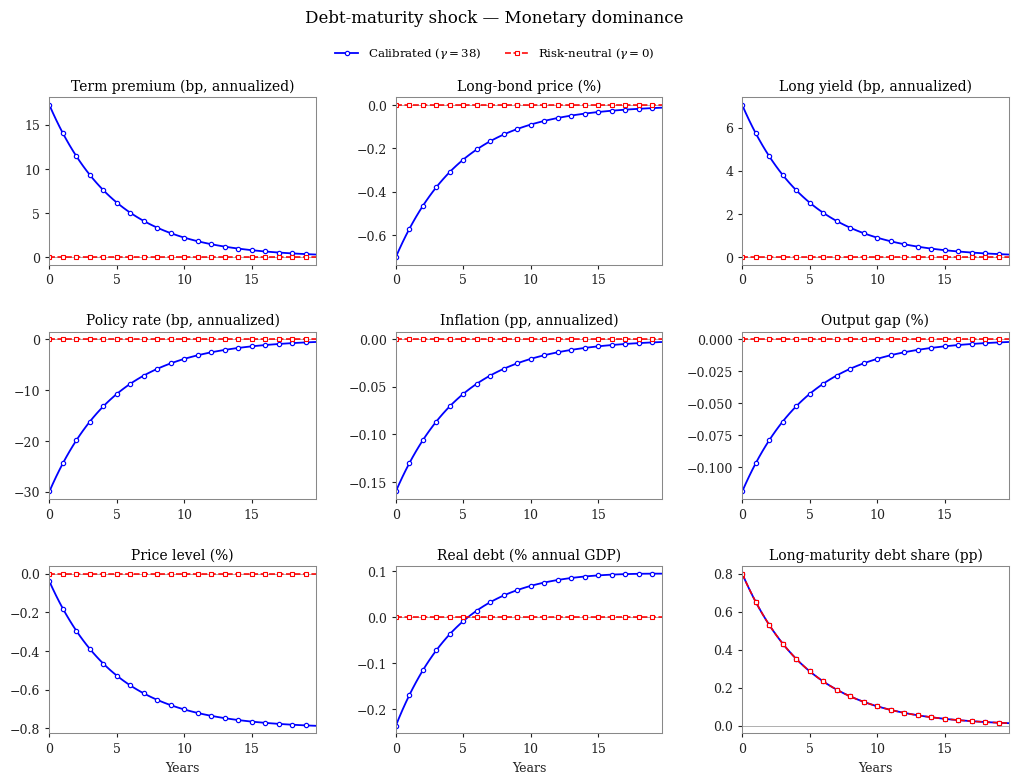

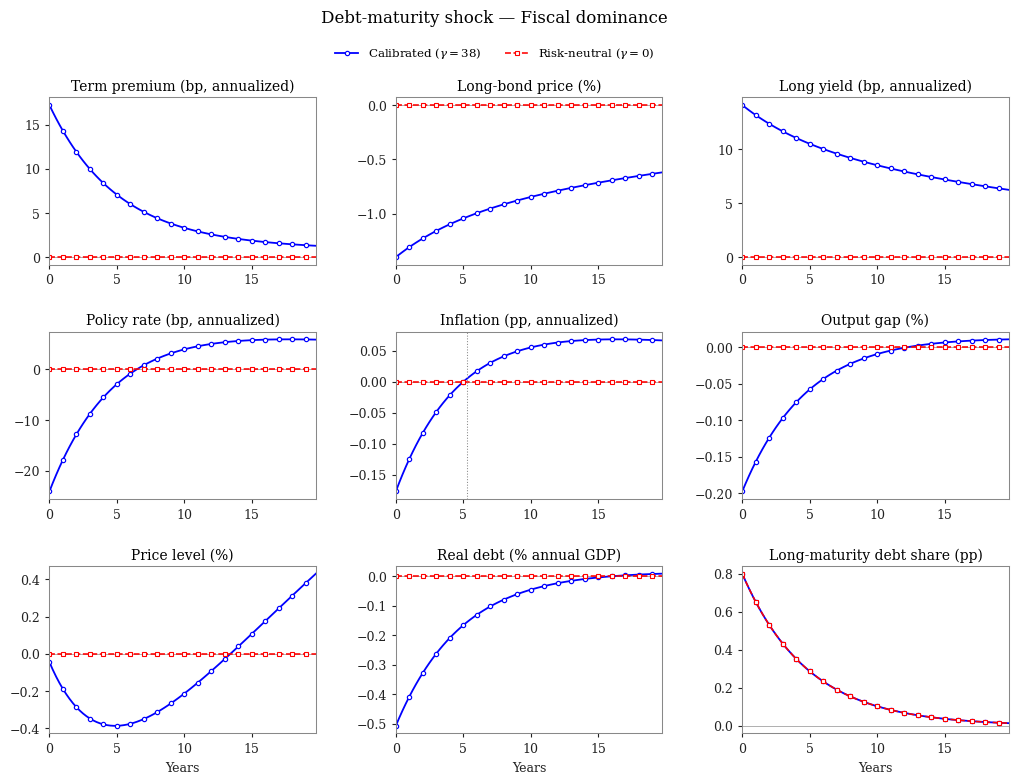

In [30]:
def plot_regime(regime, horizon=80, marker_every=4):
    risk = scale_irf(RESULTS[(regime, 'risky')]['irf'])
    base = scale_irf(RESULTS[(regime, 'neutral')]['irf'])
    # The reference figure uses small boxed panels, slim lines, and discrete markers.
    fig, axs = plt.subplots(3, 3, figsize=(10.6, 8.0), sharex=True)
    quarters = np.arange(min(horizon, len(risk)))
    years = quarters / 4
    for ax, (key, label) in zip(axs.flat, LABELS):
        ax.axhline(0, color='#AAAAAA', lw=0.65, zorder=0)
        ax.plot(years, risk[key].iloc[:len(years)].to_numpy(),
                '-', color=BLUE, lw=1.3, marker='o', markersize=3.1,
                markerfacecolor='white', markeredgecolor=BLUE,
                markeredgewidth=0.85, markevery=marker_every,
                label=r'Calibrated ($\gamma=38$)')
        ax.plot(years, base[key].iloc[:len(years)].to_numpy(),
                '--', color=RED, lw=1.15, marker='s', markersize=3.0,
                markerfacecolor='white', markeredgecolor=RED,
                markeredgewidth=0.8, markevery=marker_every,
                label=r'Risk-neutral ($\gamma=0$)')
        ax.set_title(label, fontsize=10, pad=5)
        ax.set_xlim(0, years[-1])
        ax.set_xticks(np.arange(0, years[-1] + 0.1, 5))
        ax.grid(False)
        ax.tick_params(labelbottom=True)
    first_positive = np.flatnonzero(RESULTS[(regime, 'risky')]['irf']['pi'].to_numpy() > 1e-12)
    if regime == 'FD' and len(first_positive) and first_positive[0] < len(years):
        t = first_positive[0] / 4
        axs[1, 1].axvline(t, color='#888888', lw=0.75, ls=':')
    for ax in axs[-1]:
        ax.set_xlabel('Years', fontsize=9)
    title = {'MD': 'Monetary dominance', 'FD': 'Fiscal dominance'}[regime]
    fig.suptitle(f'Debt-maturity shock — {title}', fontsize=12, y=.99)
    handles, labels = axs[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5, .958),
               ncol=2, frameon=False, fontsize=8.5)
    fig.subplots_adjust(left=.08, right=.985, bottom=.085, top=.88,
                        wspace=.30, hspace=.40)
    plt.show()
    return fig

for reg in REGIMES:
    plot_regime(reg)


## Fixed-Point Convergence

$$
 \left|\mathcal T(V_L^{(n)})-V_L^{(n)}\right|\longrightarrow 0
$$

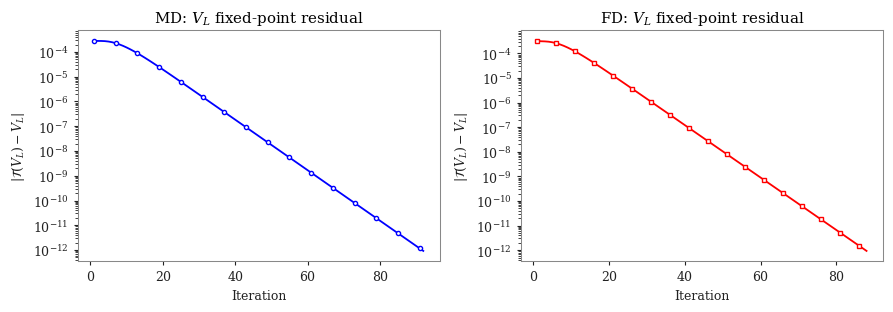

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, reg, color, marker in zip(axes, REGIMES, (BLUE, RED), ('o', 's')):
    hist = RESULTS[(reg, 'risky')]['convergence']
    ax.semilogy(hist['iteration'], np.maximum(hist['error'], 1e-18),
                color=color, lw=1.3, marker=marker, markersize=3,
                markerfacecolor='white', markevery=max(1, len(hist)//15))
    ax.set_title(f'{reg}: $V_L$ fixed-point residual')
    ax.set_xlabel('Iteration')
    ax.set_ylabel(r'$|\mathcal{T}(V_L)-V_L|$')
    ax.grid(False)
fig.tight_layout()
plt.show()
